
# Flight Fare Prediction Using Machine Learning

## 1. Project Introduction

Flight ticket prices are highly dynamic and can vary depending on several factors, including airline, journey date, departure time, arrival time, flight duration, source, destination, and number of stops.

Predicting flight fares accurately can help customers make informed travel decisions and assist airlines in understanding the factors influencing ticket pricing.

This project focuses on analyzing flight fare data using Exploratory Data Analysis (EDA) techniques and developing Machine Learning regression models to estimate flight ticket prices based on journey-related features.

## 2. Business Problem Understanding

Flight ticket prices are often unpredictable for travelers. The same journey may have different fares depending on various travel-related factors.

The objective is to analyze these factors and develop a predictive model that estimates flight ticket prices based on the available journey information.

## 3. Project Objectives

- Perform comprehensive Exploratory Data Analysis on the flight fare dataset.
- Identify the factors influencing flight ticket prices.
- Clean and preprocess the dataset.
- Perform feature engineering to extract meaningful information.
- Develop multiple Machine Learning regression models.
- Compare model performance using appropriate evaluation metrics.
- Select and recommend the best-performing model for production consideration.
- Document data challenges, solutions, and business insights.

## 4. Business Use Cases

- Help customers estimate flight ticket fares before planning their journeys.
- Help travelers make informed decisions using journey-related information.
- Help airlines understand the relationship between flight characteristics and ticket prices.
- Support data-driven analysis of airline pricing patterns.


In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [2]:

# Loading the Flight Fare Dataset

from pathlib import Path
import pandas as pd

# Define the project folder
project_folder = Path(
    r"C:\Users\Rakshitha\OneDrive\Desktop\Flight-Fare-Prediction"
)

# Define the raw dataset location
file_path = project_folder / "flight-fare" / "Flight_Fare.xlsx"

# Verify and load the dataset
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [3]:
# Checking dataset structure and data quality

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES IN EACH COLUMN")
print(df.isnull().sum())

print("\nTOTAL DUPLICATE ROWS")
print(df.duplicated().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB

MISSING VALUES IN EACH COLUMN
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_In

In [4]:
# Displaying records containing missing values

missing_records = df[df.isnull().any(axis=1)]

print("Records containing missing values:")
display(missing_records)

Records containing missing values:


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [5]:
# Inspecting duplicate records

duplicate_records = df[df.duplicated(keep=False)]

print("Total rows involved in duplicate groups:",
      len(duplicate_records))

display(duplicate_records.head(10))

Total rows involved in duplicate groups: 415


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
33,Jet Airways,15/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,14:35,12:35 16 Jun,22h,2 stops,In-flight meal not included,10919
49,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,19:00 28 Jun,19h 55m,2 stops,In-flight meal not included,11150
73,Jet Airways,24/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,12:35 25 Jun,13h 30m,2 stops,No info,12819
81,Jet Airways,24/03/2019,Banglore,New Delhi,BLR → DEL,19:55,22:35,2h 40m,non-stop,No info,7229
87,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,04:25 07 Jun,18h 45m,2 stops,No info,13014
136,Jet Airways,6/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,06:45,04:25 07 Jun,21h 40m,2 stops,No info,13376
137,Air India,27/06/2019,Delhi,Cochin,DEL → GOI → BOM → COK,22:00,19:15 28 Jun,21h 15m,2 stops,No info,10441
209,Jet Airways,18/05/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,04:25 20 May,29h 20m,2 stops,No info,15129
224,Jet Airways,9/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,05:30,04:25 10 Jun,22h 55m,2 stops,No info,13014
251,Air India,1/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,19:45,19:15 02 Jun,23h 30m,2 stops,No info,10651


In [6]:
# Removing exact duplicate records

df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Original dataset shape: (10683, 11)
Dataset shape after removing duplicates: (10463, 11)
Remaining duplicate rows: 0


In [7]:
# Checking missing values after duplicate removal

print("Missing values in cleaned dataset:")
print(df_clean.isnull().sum())

print("\nRows containing missing values:")
display(df_clean[df_clean.isnull().any(axis=1)])

Missing values in cleaned dataset:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

Rows containing missing values:


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [8]:
# Removing the record with missing flight information

df_clean = df_clean.dropna(subset=['Route', 'Total_Stops']).copy()

print("Dataset shape after handling missing values:", df_clean.shape)

print("\nMissing values remaining:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows remaining:")
print(df_clean.duplicated().sum())

Dataset shape after handling missing values: (10462, 11)

Missing values remaining:
0

Duplicate rows remaining:
0


In [9]:
# Inspecting unique categorical values

categorical_columns = [
    'Airline',
    'Source',
    'Destination',
    'Total_Stops',
    'Additional_Info'
]

for column in categorical_columns:
    print(f"\n{column}")
    print("Unique values:", df_clean[column].nunique())
    print(df_clean[column].unique())


Airline
Unique values: 12
['IndiGo' 'Air India' 'Jet Airways' 'SpiceJet' 'Multiple carriers' 'GoAir'
 'Vistara' 'Air Asia' 'Vistara Premium economy' 'Jet Airways Business'
 'Multiple carriers Premium economy' 'Trujet']

Source
Unique values: 5
['Banglore' 'Kolkata' 'Delhi' 'Chennai' 'Mumbai']

Destination
Unique values: 6
['New Delhi' 'Banglore' 'Cochin' 'Kolkata' 'Delhi' 'Hyderabad']

Total_Stops
Unique values: 5
['non-stop' '2 stops' '1 stop' '3 stops' '4 stops']

Additional_Info
Unique values: 10
['No info' 'In-flight meal not included' 'No check-in baggage included'
 '1 Short layover' 'No Info' '1 Long layover' 'Change airports'
 'Business class' 'Red-eye flight' '2 Long layover']


In [10]:
# Standardizing Additional_Info categories

df_clean['Additional_Info'] = (
    df_clean['Additional_Info']
    .str.strip()
    .replace({
        'No Info': 'No info'
    })
)

print("Unique Additional_Info categories after standardization:")
print(df_clean['Additional_Info'].unique())

print("\nTotal unique categories:",
      df_clean['Additional_Info'].nunique())

Unique Additional_Info categories after standardization:
['No info' 'In-flight meal not included' 'No check-in baggage included'
 '1 Short layover' '1 Long layover' 'Change airports' 'Business class'
 'Red-eye flight' '2 Long layover']

Total unique categories: 9


In [11]:
# Statistical summary of flight prices

print("PRICE STATISTICAL SUMMARY")
display(df_clean['Price'].describe())

print("\nPRICE DISTRIBUTION")
print("Minimum Price:", df_clean['Price'].min())
print("Maximum Price:", df_clean['Price'].max())
print("Average Price:", round(df_clean['Price'].mean(), 2))
print("Median Price:", df_clean['Price'].median())

PRICE STATISTICAL SUMMARY


count    10462.000000
mean      9026.790289
std       4624.849541
min       1759.000000
25%       5224.000000
50%       8266.000000
75%      12344.750000
max      79512.000000
Name: Price, dtype: float64


PRICE DISTRIBUTION
Minimum Price: 1759
Maximum Price: 79512
Average Price: 9026.79
Median Price: 8266.0


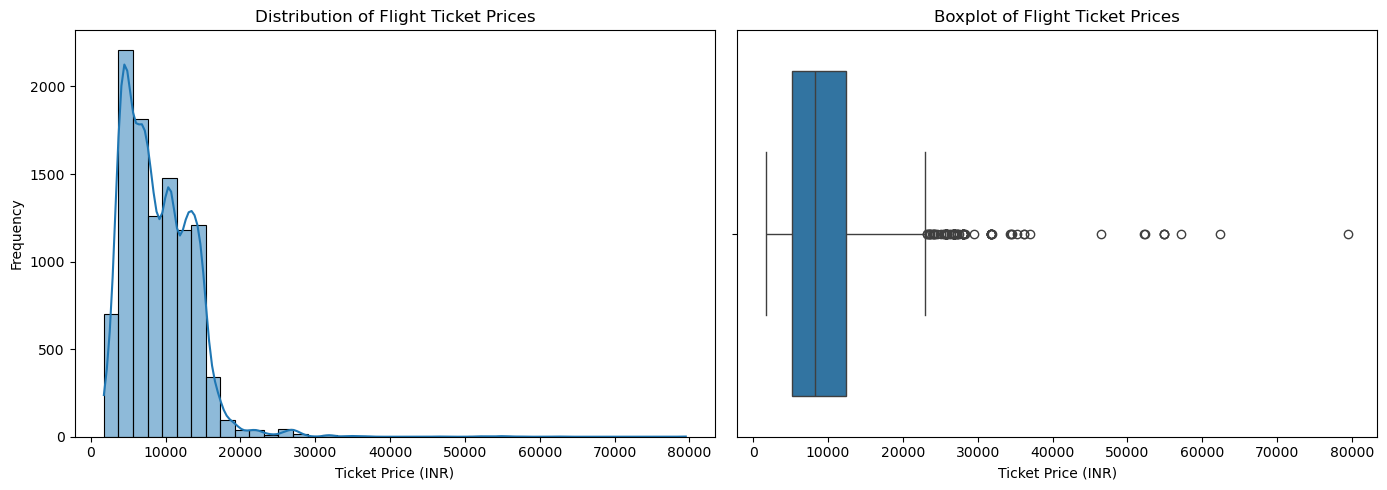

In [13]:
# Visualizing flight price distribution

plt.figure(figsize=(14, 5))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(df_clean['Price'], bins=40, kde=True)
plt.title('Distribution of Flight Ticket Prices')
plt.xlabel('Ticket Price (INR)')
plt.ylabel('Frequency')

# Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean['Price'])
plt.title('Boxplot of Flight Ticket Prices')
plt.xlabel('Ticket Price (INR)')

plt.tight_layout()
plt.show()

### Price Distribution – Key Observations

1. The flight ticket prices show a right-skewed distribution.
2. Most ticket prices are concentrated approximately between ₹3,000 and ₹15,000.
3. The average ticket price is ₹9,026.79, while the median is ₹8,266.
4. The boxplot indicates the presence of several potential high-price outliers.
5. The maximum observed ticket price is ₹79,512.
6. High-price observations will be investigated before deciding whether any outlier treatment is necessary.

**Business Insight:** Flight ticket prices vary considerably across observations. Understanding the factors influencing these variations can help build a more reliable flight fare prediction model.

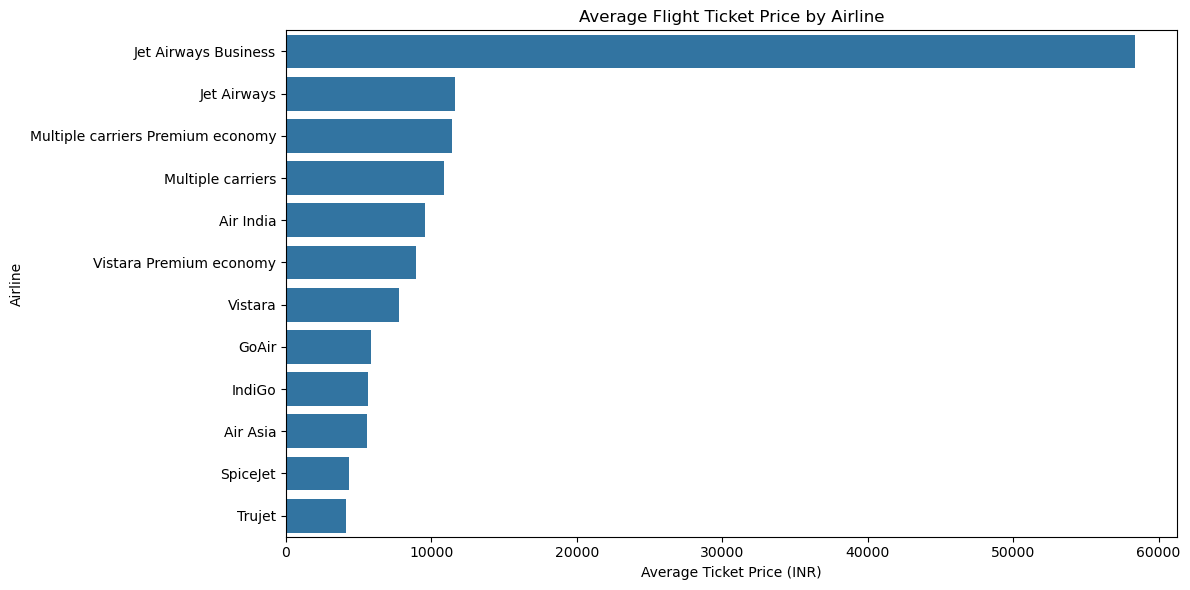

In [14]:
# Average flight ticket price by airline

airline_prices = (
    df_clean.groupby('Airline')['Price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=airline_prices.values,
    y=airline_prices.index
)

plt.title('Average Flight Ticket Price by Airline')
plt.xlabel('Average Ticket Price (INR)')
plt.ylabel('Airline')

plt.tight_layout()
plt.show()

In [15]:
# Displaying average ticket prices by airline

print("Average Flight Ticket Price by Airline:")
display(airline_prices.round(2))

print("\nMost Expensive Airline:")
print(airline_prices.idxmax(), "₹", round(airline_prices.max(), 2))

print("\nMost Affordable Airline:")
print(airline_prices.idxmin(), "₹", round(airline_prices.min(), 2))

Average Flight Ticket Price by Airline:


Airline
Jet Airways Business                 58358.67
Jet Airways                          11599.02
Multiple carriers Premium economy    11418.85
Multiple carriers                    10902.68
Air India                             9556.61
Vistara Premium economy               8962.33
Vistara                               7801.36
GoAir                                 5861.06
IndiGo                                5668.47
Air Asia                              5590.26
SpiceJet                              4335.84
Trujet                                4140.00
Name: Price, dtype: float64


Most Expensive Airline:
Jet Airways Business ₹ 58358.67

Most Affordable Airline:
Trujet ₹ 4140.0


In [16]:
# Comparing airline-wise average prices and record counts

airline_analysis = (
    df_clean.groupby('Airline')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='mean', ascending=False)
)

airline_analysis.columns = [
    'Number_of_Flights',
    'Average_Price',
    'Median_Price'
]

display(airline_analysis.round(2))

,Number_of_Flights,Average_Price,Median_Price
Airline,,,
Jet Airways Business,6,58358.67,54747.0
Jet Airways,3700,11599.02,11134.0
Multiple carriers Premium economy,13,11418.85,11269.0
Multiple carriers,1196,10902.68,10197.0
Air India,1694,9556.61,9316.0
Vistara Premium economy,3,8962.33,9125.0
Vistara,478,7801.36,7980.0
GoAir,194,5861.06,5135.0
IndiGo,2043,5668.47,5000.0


### Airline-wise Price Analysis – Key Findings

1. Jet Airways Business recorded the highest average ticket price of ₹58,358.67, based on only 6 observations.
2. Jet Airways recorded an average price of ₹11,599.02 across 3,700 observations.
3. IndiGo had 2,043 observations, with an average fare of ₹5,668.47.
4. SpiceJet recorded an average fare of ₹4,335.84 across 815 observations.
5. Trujet had only one observation, so its average fare of ₹4,140 cannot be considered representative.

**Business Insight:** Airline selection appears to be an important factor associated with flight ticket prices. However, average prices must be interpreted alongside the number of observations available for each airline.

In [17]:
# Average flight price based on number of stops

stops_analysis = (
    df_clean.groupby('Total_Stops')['Price']
    .agg(['count', 'mean', 'median'])
)

display(stops_analysis.round(2))

,count,mean,median
Total_Stops,,,
1 stop,5625,10594.12,10262.0
2 stops,1318,12761.10,12723.0
3 stops,43,13260.67,13007.0
4 stops,1,17686.00,17686.0
non-stop,3475,5018.51,4667.0


### Flight Price Analysis Based on Number of Stops

**Key Findings:**

1. Non-stop flights have an average ticket price of ₹5,018.51.
2. One-stop flights have an average ticket price of ₹10,594.12.
3. Two-stop flights have an average ticket price of ₹12,761.10.
4. Three-stop flights have an average ticket price of ₹13,260.67.
5. Four-stop flights have only one observation, making their average price unsuitable for general conclusions.

**Business Insight:** Flight prices show an increasing pattern across stop categories in this dataset. The number of stops is a potentially useful feature for flight fare prediction.

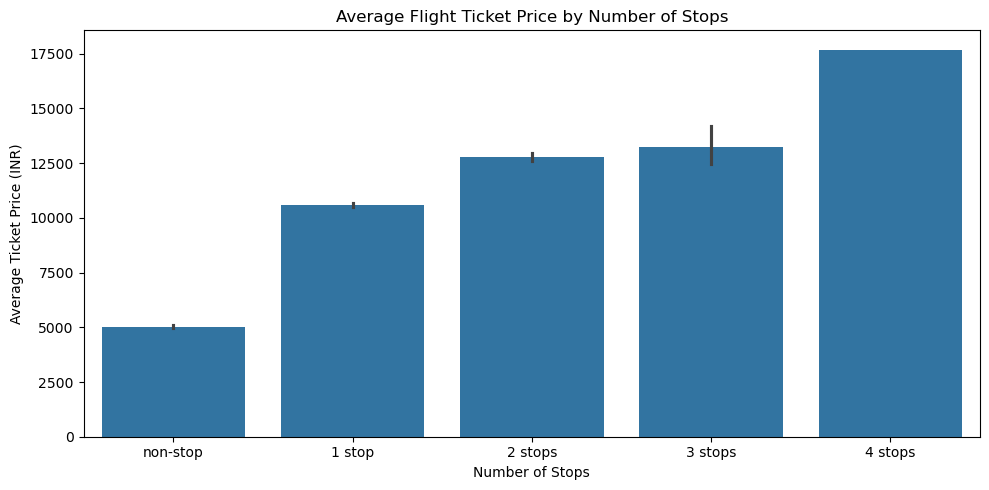

In [18]:
# Visualizing average ticket price by number of stops

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='Total_Stops',
    y='Price',
    order=['non-stop', '1 stop', '2 stops', '3 stops', '4 stops']
)

plt.title('Average Flight Ticket Price by Number of Stops')
plt.xlabel('Number of Stops')
plt.ylabel('Average Ticket Price (INR)')

plt.tight_layout()
plt.show()

### Business Insight – Flight Price vs Number of Stops

The analysis indicates that non-stop flights have the lowest average ticket price, while flights with one or more stops generally show higher average fares. However, the categories with three and four stops contain very few observations, so their average prices may not represent typical market fares.

This suggests that the number of stops is an important feature to investigate when estimating flight prices. Other factors, such as airline, route, journey date and duration, may also influence the fare.

In [20]:
# Analysing average flight price by source city

source_analysis = (
    df_clean.groupby('Source')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='mean', ascending=False)
)

source_analysis

,count,mean,median
Source,,,
Delhi,4345,10461.600690,10262.0
Kolkata,2860,9143.083566,9345.0
Banglore,2179,8022.872877,6121.0
Mumbai,697,5059.708752,3342.0
Chennai,381,4789.892388,3850.0


### Business Insight – Flight Price vs Source City

The analysis shows that flights departing from Delhi have the highest average ticket price (₹10,461.60), followed by Kolkata (₹9,143.08). Chennai has the lowest average ticket price (₹4,789.89).

The number of observations also varies across source cities. Delhi has the highest number of records, while Chennai has the lowest.

This indicates that the departure city may be a useful feature for flight fare prediction. However, ticket prices are influenced by multiple factors, so source city should not be considered independently.

In [21]:
# Analysing average flight price by destination city

destination_analysis = (
    df_clean.groupby('Destination')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='mean', ascending=False)
)

destination_analysis

,count,mean,median
Destination,,,
New Delhi,914,12007.421225,11003.0
Cochin,4345,10461.600690,10262.0
Banglore,2860,9143.083566,9345.0
Delhi,1265,5143.918577,4823.0
Hyderabad,697,5059.708752,3342.0
Kolkata,381,4789.892388,3850.0


### Business Insight – Flight Price vs Destination City

The analysis indicates that New Delhi has the highest average ticket price (₹12,007.42), while Kolkata has the lowest average ticket price (₹4,789.89).

Cochin has the highest number of observations, with 4,345 records. The number of observations varies considerably across destinations.

The results suggest that destination city can be a useful feature for flight fare prediction. However, the relationship between source and destination should also be investigated to understand route-specific pricing patterns.

In [22]:
# Analysing flight duration
df_clean['Duration'].value_counts().head(15)

Duration
2h 50m     544
1h 30m     386
2h 45m     335
2h 55m     332
2h 35m     329
3h         260
2h 20m     238
2h 30m     220
2h 40m     156
1h 25m     135
2h 15m     135
2h 25m      98
13h 20m     89
3h 15m      88
7h 30m      86
Name: count, dtype: int64

### Business Insight – Flight Duration Analysis

The most frequently observed flight duration is 2 hours and 50 minutes, appearing in 544 records. Several other common durations fall between 1 and 3 hours.

Longer-duration flights are also present in the dataset. Since duration is currently stored as text, it must be converted into a numerical representation (total minutes) during feature engineering before model training.

Flight duration may help the prediction model identify differences in fares across journeys.

In [23]:
# Checking the shortest and longest flight durations

duration_minutes = (
    df_clean['Duration']
    .str.extract(r'(?:(\d+)h)?\s*(?:(\d+)m)?')
    .fillna(0)
    .astype(int)
)

df_clean['Duration_Minutes'] = (
    duration_minutes[0] * 60 + duration_minutes[1]
)

print("Shortest flight duration:", df_clean['Duration_Minutes'].min(), "minutes")
print("Longest flight duration:", df_clean['Duration_Minutes'].max(), "minutes")

df_clean['Duration_Minutes'].describe()

Shortest flight duration: 5 minutes
Longest flight duration: 2860 minutes


count    10462.000000
mean       629.781591
std        500.699045
min          5.000000
25%        170.000000
50%        505.000000
75%        910.000000
max       2860.000000
Name: Duration_Minutes, dtype: float64

In [24]:
# Investigating unusually short and long flight durations

print("Flights with duration below 30 minutes:")

display(
    df_clean[df_clean['Duration_Minutes'] < 30][
        ['Airline', 'Source', 'Destination', 'Duration', 'Price']
    ]
)

print("\nFlights with duration above 24 hours:")

display(
    df_clean[df_clean['Duration_Minutes'] > 1440][
        ['Airline', 'Source', 'Destination', 'Duration', 'Price']
    ]
)

Flights with duration below 30 minutes:


,Airline,Source,Destination,Duration,Price
6474,Air India,Mumbai,Hyderabad,5m,17327



Flights with duration above 24 hours:


,Airline,Source,Destination,Duration,Price
8,Jet Airways,Banglore,New Delhi,25h 30m,11087
15,Air India,Delhi,Cochin,26h 35m,14011
51,Jet Airways,Kolkata,Banglore,25h 20m,12121
59,Vistara,Mumbai,Hyderabad,25h 5m,12395
61,Air India,Delhi,Cochin,27h 20m,5117
...,...,...,...,...,...
10642,Air India,Kolkata,Banglore,26h 50m,11222
10648,Air India,Delhi,Cochin,26h 20m,13801
10652,Air India,Delhi,Cochin,25h 35m,9790
10666,Jet Airways,Delhi,Cochin,24h 45m,10262


In [25]:
# Inspecting the complete record with an unusually short duration

df_clean.loc[6474].to_frame(name='Value')

,Value
Airline,Air India
Date_of_Journey,6/03/2019
Source,Mumbai
Destination,Hyderabad
Route,BOM → GOI → PNQ → HYD
Dep_Time,16:50
Arrival_Time,16:55
Duration,5m
Total_Stops,2 stops
Additional_Info,No info


### Data Quality Issue – Unusually Short Flight Duration

During duration analysis, one record was identified with a flight duration of only 5 minutes.

The record represents an Air India journey from Mumbai to Hyderabad through the route BOM → GOI → PNQ → HYD, with two stops. Its departure time is 16:50 and arrival time is 16:55.

This duration is inconsistent with the recorded route and number of stops. Since the actual journey duration cannot be reliably recovered from the available data, the record will be excluded from the modelling dataset rather than assigning an estimated value.

In [26]:
# Creating a separate dataset for modelling
# Excluding the single record with an unrealistic 5-minute duration

df_model = df_clean[df_clean['Duration_Minutes'] >= 30].copy()

print("Original cleaned dataset shape:", df_clean.shape)
print("Modelling dataset shape:", df_model.shape)
print("Records removed:", len(df_clean) - len(df_model))

Original cleaned dataset shape: (10462, 12)
Modelling dataset shape: (10461, 12)
Records removed: 1


### Final Data Cleaning Summary

The original dataset contained 10,683 records and 11 columns.

The following cleaning operations were performed:

1. Removed 220 exact duplicate records.
2. Removed one record with missing Route and Total_Stops values.
3. Standardized the Additional_Info category capitalization.
4. Converted flight duration into numerical minutes.
5. Identified and excluded one unrealistic 5-minute duration record from the modelling dataset.

The resulting modelling dataset contains 10,461 records and 12 columns.

The original dataset and cleaned dataset were preserved separately to maintain data traceability.

In [27]:
# Extracting journey month from Date_of_Journey

df_model['Journey_Month'] = pd.to_datetime(
    df_model['Date_of_Journey'],
    dayfirst=True
).dt.month

# Analysing average ticket price by journey month

month_analysis = (
    df_model.groupby('Journey_Month')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='Journey_Month')
)

month_analysis

,count,mean,median
Journey_Month,,,
3,2677,10692.920060,9748.0
4,1078,5766.545455,5073.0
5,3395,9029.239764,8662.0
6,3311,8736.152522,8510.0


### Business Insight – Flight Price vs Journey Month

The analysis indicates that March has the highest average ticket price (₹10,692.92), while April has the lowest average ticket price (₹5,766.55).

May contains the highest number of observations, with 3,395 records, followed by June with 3,311 records.

The variation in average ticket prices across journey months suggests that journey month may be an important feature for flight fare prediction. However, the dataset covers only March to June 2019, so these findings should not be generalized to all months or years.

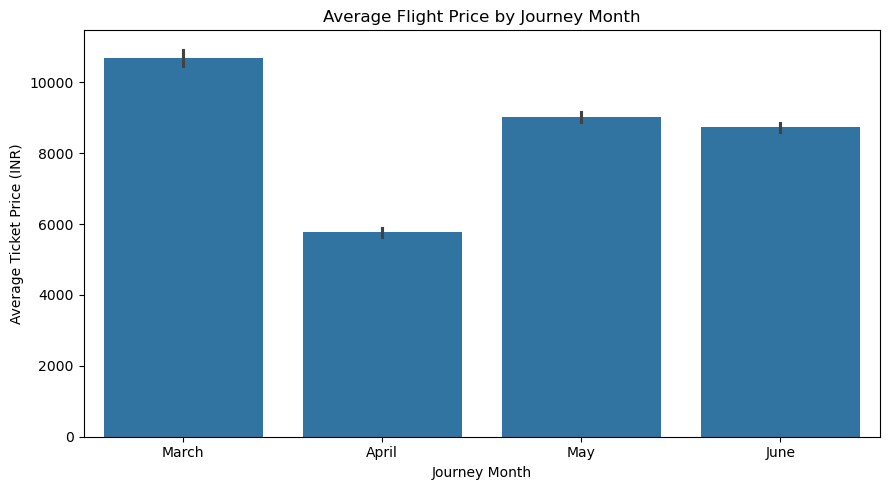

In [28]:
# Visualizing average flight price by journey month

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_model,
    x='Journey_Month',
    y='Price',
    order=[3, 4, 5, 6]
)

plt.title('Average Flight Price by Journey Month')
plt.xlabel('Journey Month')
plt.ylabel('Average Ticket Price (INR)')
plt.xticks([0, 1, 2, 3], ['March', 'April', 'May', 'June'])

plt.tight_layout()
plt.show()

In [29]:
# Extracting departure hour from Dep_Time

df_model['Dep_Hour'] = pd.to_datetime(
    df_model['Dep_Time'],
    format='%H:%M'
).dt.hour

# Analysing average flight price by departure hour

departure_analysis = (
    df_model.groupby('Dep_Hour')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='Dep_Hour')
)

departure_analysis

,count,mean,median
Dep_Hour,,,
0,40,7615.075000,4353.5
1,37,4354.621622,4077.0
2,194,8419.974227,6386.0
3,24,10474.625000,10197.0
4,169,7266.520710,6171.0
5,582,9480.309278,9134.0
6,675,8252.195556,7229.0
7,863,8485.902665,7618.0
8,694,10073.923631,9663.0


### Business Insight – Flight Price vs Departure Time

The analysis indicates that departure time is associated with variations in average flight ticket prices.

The 03:00 AM departure hour has the highest average fare (₹10,474.63), although it contains only 24 observations. The 09:00 AM departure hour has the highest number of records, with 886 flights.

The results suggest that departure hour may be a useful feature for flight fare prediction. However, differences in sample sizes and other factors such as airline, route and number of stops should also be considered.

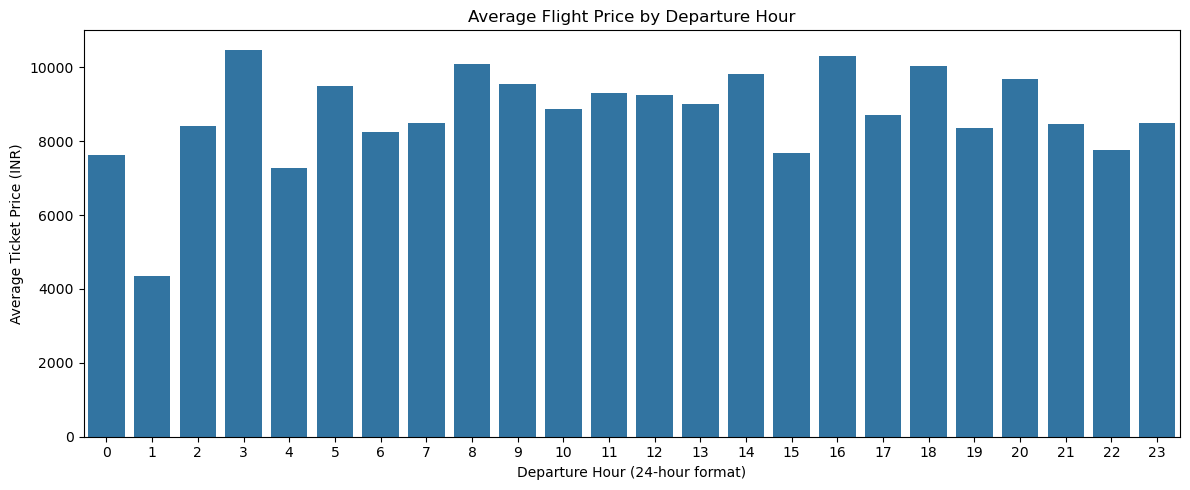

In [30]:
# Visualizing average flight price by departure hour

plt.figure(figsize=(12, 5))

sns.barplot(
    data=df_model,
    x='Dep_Hour',
    y='Price',
    errorbar=None
)

plt.title('Average Flight Price by Departure Hour')
plt.xlabel('Departure Hour (24-hour format)')
plt.ylabel('Average Ticket Price (INR)')
plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [31]:
# Extracting arrival hour from Arrival_Time

df_model['Arrival_Hour'] = pd.to_datetime(
    df_model['Arrival_Time'],
    format='mixed'
).dt.hour

# Analysing average flight price by arrival hour

arrival_analysis = (
    df_model.groupby('Arrival_Hour')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='Arrival_Hour')
)

arrival_analysis

,count,mean,median
Arrival_Hour,,,
0,322,5642.447205,4174.0
1,525,9636.845714,7530.0
2,79,5151.886076,4591.0
3,47,4934.638298,4423.0
4,761,11355.286465,12373.0
5,66,15532.151515,13555.0
6,51,5819.470588,4777.0
7,414,7796.538647,6923.5
8,468,8051.175214,7092.0


### Business Insight – Flight Price vs Arrival Time

The analysis indicates variations in average flight ticket prices across different arrival hours.

The 05:00 AM arrival hour has the highest average fare (₹15,532.15), with 66 observations. The 07:00 PM arrival hour has the highest number of records, with 1,554 flights.

These findings suggest that arrival hour may be a useful feature for flight fare prediction. However, differences in sample sizes and other journey characteristics should be considered when interpreting the results.

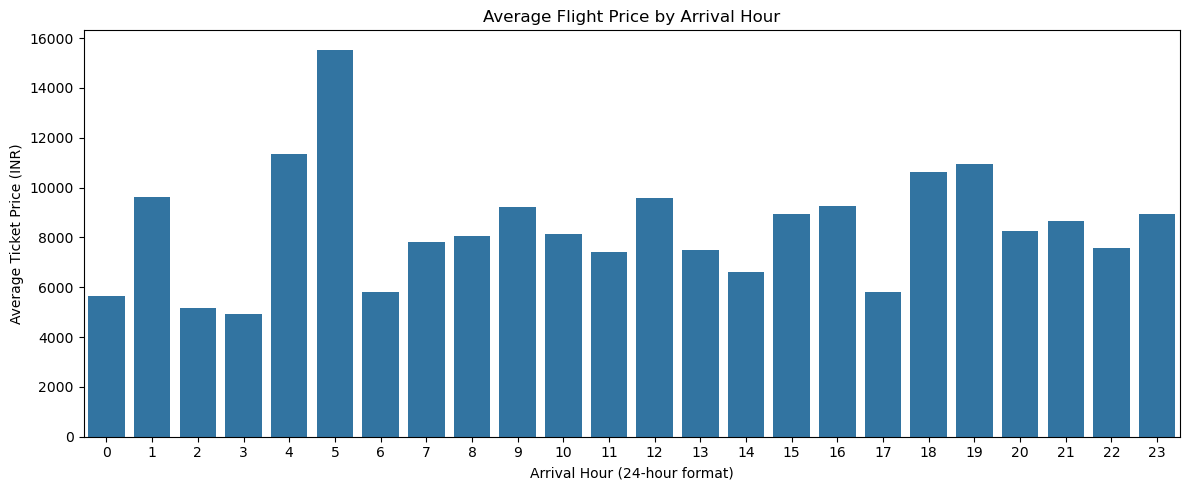

In [32]:
# Visualizing average flight price by arrival hour

plt.figure(figsize=(12, 5))

sns.barplot(
    data=df_model,
    x='Arrival_Hour',
    y='Price',
    errorbar=None
)

plt.title('Average Flight Price by Arrival Hour')
plt.xlabel('Arrival Hour (24-hour format)')
plt.ylabel('Average Ticket Price (INR)')
plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [33]:
# Analysing the most frequently used flight routes

route_analysis = (
    df_model['Route']
    .value_counts()
    .head(15)
)

route_analysis

Route
DEL → BOM → COK          2376
BLR → DEL                1536
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
CCU → DEL → BLR           565
BLR → BOM → DEL           402
MAA → CCU                 381
DEL → HYD → COK           326
DEL → BLR → COK           232
DEL → COK                 213
DEL → JAI → BOM → COK     183
DEL → MAA → COK           146
DEL → AMD → BOM → COK     144
DEL → IDR → BOM → COK      90
Name: count, dtype: int64

### Business Insight – Flight Route Frequency Analysis

The most frequently observed route is DEL → BOM → COK, with 2,376 records, followed by BLR → DEL, with 1,536 records.

Several frequently occurring routes contain intermediate stops, while others represent direct routes.

Route information provides useful details about journey patterns and may help the predictive model capture differences in flight pricing across routes.

In [34]:
# Analysing average flight price for the 15 most common routes

top_routes = df_model['Route'].value_counts().head(15).index

route_price_analysis = (
    df_model[df_model['Route'].isin(top_routes)]
    .groupby('Route')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='mean', ascending=False)
)

route_price_analysis

,count,mean,median
Route,,,
BLR → BOM → DEL,402,15723.174129,13555.0
DEL → IDR → BOM → COK,90,14038.122222,13292.0
DEL → AMD → BOM → COK,144,12630.173611,12646.0
DEL → JAI → BOM → COK,183,12210.196721,13014.0
CCU → BOM → BLR,979,11487.788560,10844.0
DEL → BOM → COK,2376,10954.205808,10262.0
CCU → DEL → BLR,565,10763.258407,10539.0
DEL → BLR → COK,232,7559.612069,6789.5
DEL → MAA → COK,146,7312.431507,7317.0


### Business Insight – Flight Price vs Route

The route-wise pricing analysis indicates considerable variation in average flight ticket prices across different routes.

Among the 15 most frequently observed routes, BLR → BOM → DEL has the highest average fare of ₹15,723.17, while BOM → HYD has the lowest average fare of ₹3,932.81.

The route DEL → BOM → COK has the highest number of observations, with 2,376 records.

These findings suggest that route information may be an important feature for flight fare prediction. Different source-destination combinations and intermediate stops may contribute to variations in ticket prices.

In [35]:
# Analysing average flight price by additional information

additional_info_analysis = (
    df_model.groupby('Additional_Info')['Price']
    .agg(['count', 'mean', 'median'])
    .sort_values(by='mean', ascending=False)
)

additional_info_analysis

,count,mean,median
Additional_Info,,,
Business class,4,56811.250000,59818.0
1 Short layover,1,26743.000000,26743.0
2 Long layover,1,26480.000000,26480.0
1 Long layover,19,22109.631579,25735.0
Change airports,7,16800.714286,15119.0
Red-eye flight,1,10873.000000,10873.0
In-flight meal not included,1926,9435.647456,10262.0
No info,8184,9073.871334,7893.0
No check-in baggage included,318,3642.465409,3841.0


### Business Insight – Flight Price vs Additional Information

The analysis indicates considerable variation in average ticket prices across Additional_Info categories.

Business class has the highest average fare of ₹56,811.25, although it contains only four observations. The No info category has the highest frequency, with 8,184 records.

The No check-in baggage included category has the lowest average fare of ₹3,642.47.

The results suggest that additional flight information may contain useful pricing-related patterns. However, categories with very few observations should be interpreted cautiously and handled appropriately during model preprocessing.

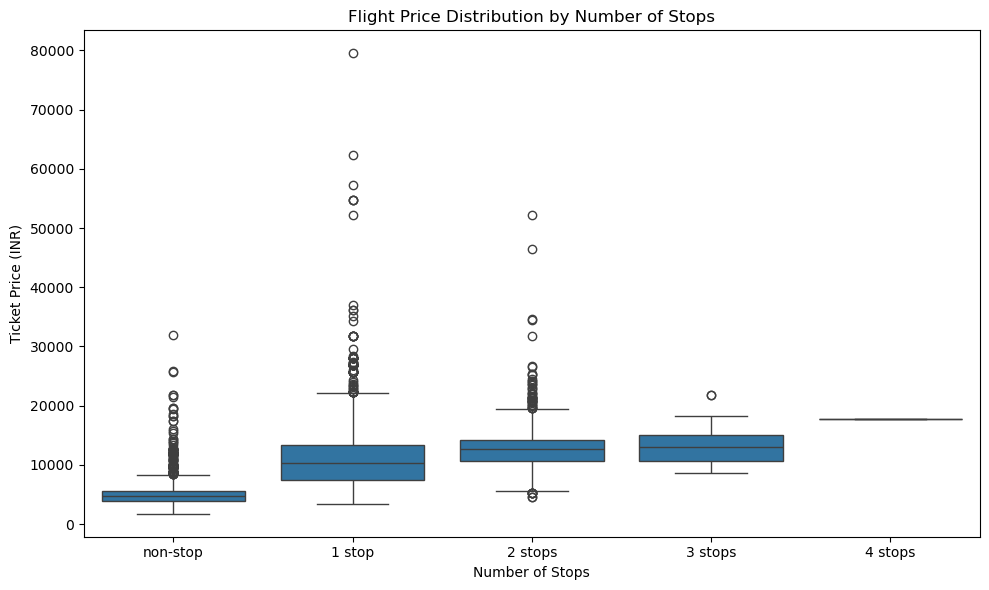

In [36]:
# Comparing flight price distributions by number of stops

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_model,
    x='Total_Stops',
    y='Price',
    order=['non-stop', '1 stop', '2 stops', '3 stops', '4 stops']
)

plt.title('Flight Price Distribution by Number of Stops')
plt.xlabel('Number of Stops')
plt.ylabel('Ticket Price (INR)')

plt.tight_layout()
plt.show()

### Business Insight – Flight Price Distribution by Number of Stops

The boxplot shows differences in ticket price distributions across flight stop categories.

Non-stop flights generally have lower median prices compared with flights involving one or more stops. One-stop and two-stop flights show higher price distributions.

Several high-price outliers are visible across categories. These observations should not be removed automatically because they may represent genuine premium or expensive flight tickets.

The number of stops appears to be a useful feature for flight fare prediction, although other journey characteristics also influence prices.

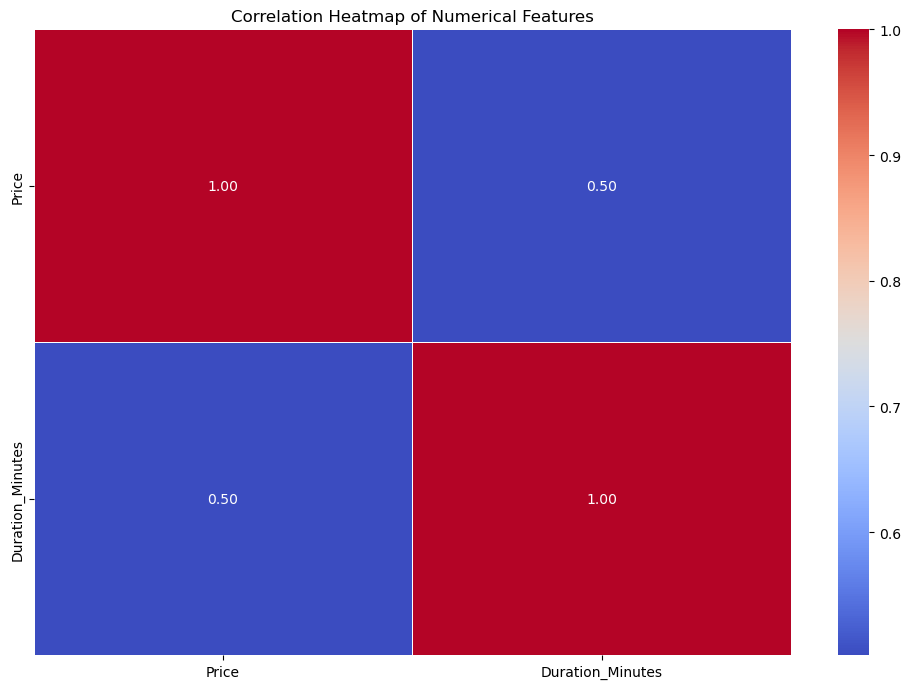

In [37]:
# Selecting numerical columns for correlation analysis

numerical_data = df_model.select_dtypes(include=['int64', 'float64'])

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')

plt.tight_layout()
plt.show()

### Business Insight – Correlation Analysis

The correlation analysis identified a moderate positive correlation of 0.50 between Duration_Minutes and Price.

This suggests that longer flight durations tend to be associated with higher ticket prices in the dataset.

However, correlation does not imply causation, and flight duration alone cannot explain ticket price variations. Other features such as airline, route, departure time, arrival time and number of stops may also contribute to pricing differences.

In [38]:
# Final inspection before feature engineering

print("Dataset shape:", df_model.shape)

print("\nColumn names:")
print(df_model.columns.tolist())

print("\nData types:")
print(df_model.dtypes)

print("\nMissing values:")
print(df_model.isnull().sum())

Dataset shape: (10461, 15)

Column names:
['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price', 'Duration_Minutes', 'Journey_Month', 'Dep_Hour', 'Arrival_Hour']

Data types:
Airline             object
Date_of_Journey     object
Source              object
Destination         object
Route               object
Dep_Time            object
Arrival_Time        object
Duration            object
Total_Stops         object
Additional_Info     object
Price                int64
Duration_Minutes     int64
Journey_Month        int32
Dep_Hour             int32
Arrival_Hour         int32
dtype: object

Missing values:
Airline             0
Date_of_Journey     0
Source              0
Destination         0
Route               0
Dep_Time            0
Arrival_Time        0
Duration            0
Total_Stops         0
Additional_Info     0
Price               0
Duration_Minutes    0
Journey_Month       0
Dep_Hour  

In [39]:
# Converting Total_Stops into numerical values

stops_mapping = {
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
}

df_model['Total_Stops'] = df_model['Total_Stops'].map(stops_mapping)

print("Total Stops conversion completed!")

print("\nUnique values after conversion:")
print(sorted(df_model['Total_Stops'].unique()))

print("\nData type:")
print(df_model['Total_Stops'].dtype)

Total Stops conversion completed!

Unique values after conversion:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Data type:
int64


In [40]:
# Converting journey date into datetime format

df_model['Date_of_Journey'] = pd.to_datetime(
    df_model['Date_of_Journey'],
    dayfirst=True
)

# Extracting journey day

df_model['Journey_Day'] = df_model['Date_of_Journey'].dt.day

print("Journey date conversion completed!")

print("\nJourney day values:")
print(sorted(df_model['Journey_Day'].unique()))

print("\nUpdated data types:")
print(df_model[['Date_of_Journey', 'Journey_Day']].dtypes)

Journey date conversion completed!

Journey day values:
[np.int32(1), np.int32(3), np.int32(6), np.int32(9), np.int32(12), np.int32(15), np.int32(18), np.int32(21), np.int32(24), np.int32(27)]

Updated data types:
Date_of_Journey    datetime64[ns]
Journey_Day                 int32
dtype: object


In [41]:
# Verifying extracted journey month and day

date_verification = df_model[
    ['Date_of_Journey', 'Journey_Month', 'Journey_Day']
].head(10)

date_verification

,Date_of_Journey,Journey_Month,Journey_Day
0,2019-03-24,3,24
1,2019-05-01,5,1
2,2019-06-09,6,9
3,2019-05-12,5,12
4,2019-03-01,3,1
5,2019-06-24,6,24
6,2019-03-12,3,12
7,2019-03-01,3,1
8,2019-03-12,3,12
9,2019-05-27,5,27


In [42]:
# Verifying departure and arrival hour extraction

time_verification = df_model[
    ['Dep_Time', 'Dep_Hour', 'Arrival_Time', 'Arrival_Hour']
].head(10)

time_verification

,Dep_Time,Dep_Hour,Arrival_Time,Arrival_Hour
0,22:20,22,01:10 22 Mar,1
1,05:50,5,13:15,13
2,09:25,9,04:25 10 Jun,4
3,18:05,18,23:30,23
4,16:50,16,21:35,21
5,09:00,9,11:25,11
6,18:55,18,10:25 13 Mar,10
7,08:00,8,05:05 02 Mar,5
8,08:55,8,10:25 13 Mar,10
9,11:25,11,19:15,19


In [43]:
# Extracting departure and arrival minutes

df_model['Dep_Minute'] = pd.to_datetime(
    df_model['Dep_Time'],
    format='%H:%M'
).dt.minute

df_model['Arrival_Minute'] = pd.to_datetime(
    df_model['Arrival_Time'],
    format='mixed'
).dt.minute

print("Time feature extraction completed!")

display(
    df_model[
        ['Dep_Time', 'Dep_Hour', 'Dep_Minute',
         'Arrival_Time', 'Arrival_Hour', 'Arrival_Minute']
    ].head(10)
)

Time feature extraction completed!


,Dep_Time,Dep_Hour,Dep_Minute,Arrival_Time,Arrival_Hour,Arrival_Minute
0,22:20,22,20,01:10 22 Mar,1,10
1,05:50,5,50,13:15,13,15
2,09:25,9,25,04:25 10 Jun,4,25
3,18:05,18,5,23:30,23,30
4,16:50,16,50,21:35,21,35
5,09:00,9,0,11:25,11,25
6,18:55,18,55,10:25 13 Mar,10,25
7,08:00,8,0,05:05 02 Mar,5,5
8,08:55,8,55,10:25 13 Mar,10,25
9,11:25,11,25,19:15,19,15


In [44]:

# Inspecting the engineered dataset

print("Dataset Shape:", df_model.shape)

print("\nColumn Names:")
print(df_model.columns.tolist())

print("\nData Types:")
display(df_model.dtypes.to_frame(name='Data Type'))

print("\nMissing Values:")
display(df_model.isnull().sum().to_frame(name='Missing Values'))


Dataset Shape: (10461, 18)

Column Names:
['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price', 'Duration_Minutes', 'Journey_Month', 'Dep_Hour', 'Arrival_Hour', 'Journey_Day', 'Dep_Minute', 'Arrival_Minute']

Data Types:


,Data Type
Airline,object
Date_of_Journey,datetime64[ns]
Source,object
Destination,object
Route,object
Dep_Time,object
Arrival_Time,object
Duration,object
Total_Stops,int64
Additional_Info,object



Missing Values:


,Missing Values
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,0
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,0
Additional_Info,0


In [45]:

# Checking categorical feature distributions

print("Number of unique routes:", df_model['Route'].nunique())

print("\nTop 15 Routes:")
display(df_model['Route'].value_counts().head(15))

print("\nAdditional Info Categories:")
display(df_model['Additional_Info'].value_counts())


Number of unique routes: 128

Top 15 Routes:


Route
DEL → BOM → COK          2376
BLR → DEL                1536
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
CCU → DEL → BLR           565
BLR → BOM → DEL           402
MAA → CCU                 381
DEL → HYD → COK           326
DEL → BLR → COK           232
DEL → COK                 213
DEL → JAI → BOM → COK     183
DEL → MAA → COK           146
DEL → AMD → BOM → COK     144
DEL → IDR → BOM → COK      90
Name: count, dtype: int64


Additional Info Categories:


Additional_Info
No info                         8184
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [46]:

# Comparing Route information with Total_Stops

df_model['Route_Stop_Count'] = (
    df_model['Route'].str.count('→')
)

print("Route stop count distribution:")
display(df_model['Route_Stop_Count'].value_counts().sort_index())

print("\nComparison between Route and Total_Stops:")
display(
    pd.crosstab(
        df_model['Route_Stop_Count'],
        df_model['Total_Stops'],
        margins=True
    )
)

Route stop count distribution:


Route_Stop_Count
1    3475
2    5625
3    1317
4      43
5       1
Name: count, dtype: int64


Comparison between Route and Total_Stops:


Total_Stops,0,1,2,3,4,All
Route_Stop_Count,,,,,,
1,3475,0,0,0,0,3475
2,0,5625,0,0,0,5625
3,0,0,1317,0,0,1317
4,0,0,0,43,0,43
5,0,0,0,0,1,1
All,3475,5625,1317,43,1,10461


In [47]:

# Checking categorical feature distributions

categorical_columns = [
    'Airline',
    'Source',
    'Destination'
]

for column in categorical_columns:
    print(f"\n{column} - Unique Categories: {df_model[column].nunique()}")
    display(df_model[column].value_counts())


Airline - Unique Categories: 12


Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1693
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64


Source - Unique Categories: 5


Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       696
Chennai      381
Name: count, dtype: int64


Destination - Unique Categories: 6


Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     696
Kolkata       381
Name: count, dtype: int64

In [48]:

# Separating input features (X) and target variable (y)

feature_columns = [
    'Airline',
    'Source',
    'Destination',
    'Route',
    'Total_Stops',
    'Additional_Info',
    'Duration_Minutes',
    'Journey_Month',
    'Journey_Day',
    'Dep_Hour',
    'Dep_Minute',
    'Arrival_Hour',
    'Arrival_Minute'
]

X = df_model[feature_columns].copy()
y = df_model['Price'].copy()

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())


Input Features Shape: (10461, 13)
Target Variable Shape: (10461,)

Input Features:


,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Duration_Minutes,Journey_Month,Journey_Day,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,0,No info,170,3,24,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2,No info,445,5,1,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2,No info,1140,6,9,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1,No info,325,5,12,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1,No info,285,3,1,16,50,21,35



Target Variable:


0     3897
1     7662
2    13882
3     6218
4    13302
Name: Price, dtype: int64

In [49]:

from sklearn.model_selection import train_test_split

# Splitting the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (8368, 13)
Testing Features: (2093, 13)

Training Target: (8368,)
Testing Target: (2093,)


In [50]:

# Identifying categorical and numerical features

categorical_features = [
    'Airline',
    'Source',
    'Destination',
    'Route',
    'Additional_Info'
]

numerical_features = [
    'Total_Stops',
    'Duration_Minutes',
    'Journey_Month',
    'Journey_Day',
    'Dep_Hour',
    'Dep_Minute',
    'Arrival_Hour',
    'Arrival_Minute'
]

print("Categorical Features:", len(categorical_features))
print(categorical_features)

print("\nNumerical Features:", len(numerical_features))
print(numerical_features)

print("\nTotal Features:", 
      len(categorical_features) + len(numerical_features))

Categorical Features: 5
['Airline', 'Source', 'Destination', 'Route', 'Additional_Info']

Numerical Features: 8
['Total_Stops', 'Duration_Minutes', 'Journey_Month', 'Journey_Day', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute']

Total Features: 13


In [51]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for categorical and numerical features

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")
print("\nCategorical Encoding: OneHotEncoder")
print("Numerical Scaling: StandardScaler")
print("Unknown Categories: Ignored")

Preprocessing pipeline created successfully!

Categorical Encoding: OneHotEncoder
Numerical Scaling: StandardScaler
Unknown Categories: Ignored


In [52]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Creating the Linear Regression pipeline

linear_regression_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

print("Linear Regression pipeline created successfully!")

Linear Regression pipeline created successfully!


In [53]:

# Training the Linear Regression model

linear_regression_pipeline.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [54]:

# Generating predictions using Linear Regression

y_pred_lr = linear_regression_pipeline.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Predicted Prices:")
print(y_pred_lr[:10])

print("\nFirst 10 Actual Prices:")
print(y_test.iloc[:10].values)


Predictions generated successfully!

First 10 Predicted Prices:
[16753.89825593  4447.34496998  4794.72521506  4112.67286667
  3064.1051737  10302.73445465  8862.22671042  7024.98876253
  9358.05139437  6180.51572556]

First 10 Actual Prices:
[17996  3873  4462  2228  4991  7229 14086  6386  6628  6934]


In [55]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluating Linear Regression

mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_lr = r2_score(y_test, y_pred_lr)

print("LINEAR REGRESSION - MODEL EVALUATION")
print("------------------------------------")
print(f"MAE  : ₹{mae_lr:.2f}")
print(f"RMSE : ₹{rmse_lr:.2f}")
print(f"R2 Score: {r2_lr:.4f}")


LINEAR REGRESSION - MODEL EVALUATION
------------------------------------
MAE  : ₹1542.86
RMSE : ₹2362.97
R2 Score: 0.7301


In [56]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

# Creating the Decision Tree pipeline

decision_tree_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=4,
            random_state=42
        ))
    ]
)

print("Decision Tree pipeline created successfully!")


Decision Tree pipeline created successfully!


In [57]:

# Training the Decision Tree model

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [58]:

# Generating predictions using Decision Tree

y_pred_dt = decision_tree_pipeline.predict(X_test)

print("Decision Tree predictions generated successfully!")

print("\nFirst 10 Predicted Prices:")
print(y_pred_dt[:10])

print("\nFirst 10 Actual Prices:")
print(y_test.iloc[:10].values)


Decision Tree predictions generated successfully!

First 10 Predicted Prices:
[15882.22222222  3923.90410959  4033.26190476  2182.2
  4275.25454545  7229.         14812.30769231  6448.975
  6095.46341463  6344.50434783]

First 10 Actual Prices:
[17996  3873  4462  2228  4991  7229 14086  6386  6628  6934]


In [59]:

# Evaluating Decision Tree Regressor

mae_dt = mean_absolute_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

r2_dt = r2_score(y_test, y_pred_dt)

print("DECISION TREE - MODEL EVALUATION")
print("--------------------------------")
print(f"MAE  : ₹{mae_dt:.2f}")
print(f"RMSE : ₹{rmse_dt:.2f}")
print(f"R2 Score: {r2_dt:.4f}")


DECISION TREE - MODEL EVALUATION
--------------------------------
MAE  : ₹871.80
RMSE : ₹1736.92
R2 Score: 0.8542


In [60]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Creating the Random Forest pipeline

random_forest_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=200,
            max_depth=20,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest pipeline created successfully!")


Random Forest pipeline created successfully!


In [61]:

# Training the Random Forest model

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [62]:
# Generating predictions using the trained Random Forest model

y_pred_rf = random_forest_pipeline.predict(X_test)

print("Random Forest predictions generated successfully!")

print("\nFirst 10 Predicted Prices:")
print(np.round(y_pred_rf[:10], 2))

print("\nFirst 10 Actual Prices:")
print(y_test.iloc[:10].values)

Random Forest predictions generated successfully!

First 10 Predicted Prices:
[15098.33  3883.6   4262.23  2466.49  4333.38  7525.95 14195.58  6271.1
  6256.21  6528.6 ]

First 10 Actual Prices:
[17996  3873  4462  2228  4991  7229 14086  6386  6628  6934]


In [63]:

# Evaluating Random Forest Regressor

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST - MODEL EVALUATION")
print("--------------------------------")
print(f"MAE  : ₹{mae_rf:.2f}")
print(f"RMSE : ₹{rmse_rf:.2f}")
print(f"R2 Score: {r2_rf:.4f}")

RANDOM FOREST - MODEL EVALUATION
--------------------------------
MAE  : ₹642.02
RMSE : ₹1349.72
R2 Score: 0.9119


In [64]:

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline

# Creating the Gradient Boosting pipeline

gradient_boosting_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42
        ))
    ]
)

print("Gradient Boosting pipeline created successfully!")


Gradient Boosting pipeline created successfully!


In [65]:

# Training the Gradient Boosting model

gradient_boosting_pipeline.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")


Gradient Boosting model trained successfully!


In [66]:

# Generating predictions using Gradient Boosting

y_pred_gb = gradient_boosting_pipeline.predict(X_test)

print("Gradient Boosting predictions generated successfully!")

print("\nFirst 10 Predicted Prices:")
print(y_pred_gb[:10])

print("\nFirst 10 Actual Prices:")
print(y_test.iloc[:10].values)

Gradient Boosting predictions generated successfully!

First 10 Predicted Prices:
[17362.20425564  4179.07128165  4881.73041425  3834.23488907
  3975.67833242  7135.78601255 12282.43178829  7414.61699928
  8026.46481207  5586.05586595]

First 10 Actual Prices:
[17996  3873  4462  2228  4991  7229 14086  6386  6628  6934]


In [67]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Model Performance")
print("-----------------------------------")
print(f"MAE  : ₹{mae_gb:.2f}")
print(f"RMSE : ₹{rmse_gb:.2f}")
print(f"R²   : {r2_gb:.4f}")

Gradient Boosting Model Performance
-----------------------------------
MAE  : ₹1277.16
RMSE : ₹1936.12
R²   : 0.8188


In [68]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        mae_lr,
        mae_dt,
        mae_rf,
        mae_gb
    ],
    'RMSE': [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_gb
    ],
    'R2 Score': [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_gb
    ]
})

model_comparison = model_comparison.sort_values(
    by='MAE',
    ascending=True
).reset_index(drop=True)

model_comparison

,Model,MAE,RMSE,R2 Score
0,Random Forest,642.017329,1349.718185,0.911937
1,Decision Tree,871.797046,1736.920671,0.854163
2,Gradient Boosting,1277.159356,1936.123028,0.818794
3,Linear Regression,1542.860455,2362.969622,0.730087


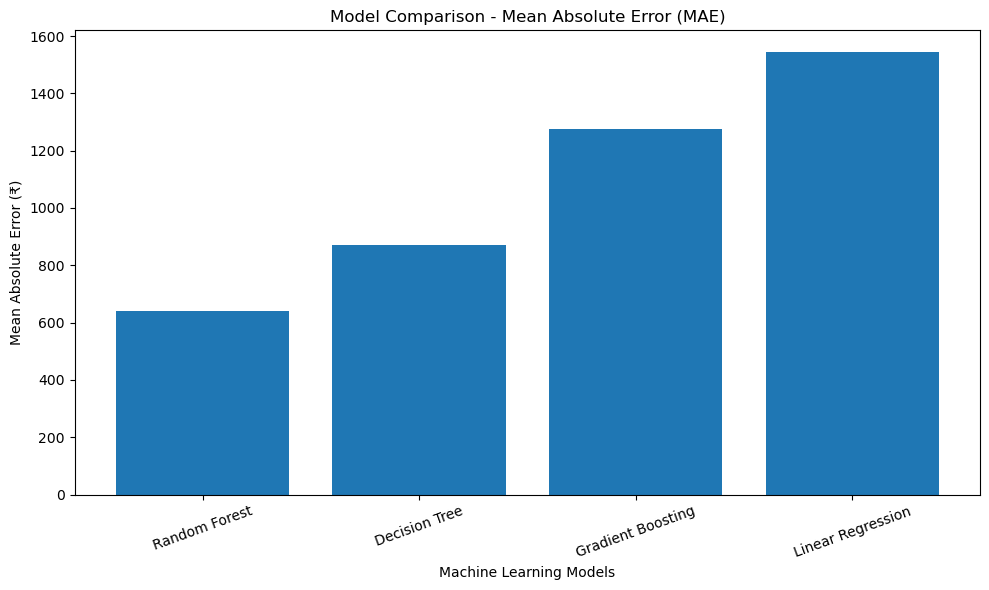

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    model_comparison['Model'],
    model_comparison['MAE']
)

plt.title('Model Comparison - Mean Absolute Error (MAE)')
plt.xlabel('Machine Learning Models')
plt.ylabel('Mean Absolute Error (₹)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [70]:
from sklearn.model_selection import cross_validate

rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'R2': 'r2'
    },
    n_jobs=-1
)

print("Random Forest - 5-Fold Cross Validation")
print("---------------------------------------")
print(
    "Average MAE: ₹",
    round(-rf_cv_results['test_MAE'].mean(), 2)
)
print(
    "Average R2:",
    round(rf_cv_results['test_R2'].mean(), 4)
)

Random Forest - 5-Fold Cross Validation
---------------------------------------
Average MAE: ₹ 697.68
Average R2: 0.8774


In [71]:
models = {
    'Linear Regression': linear_regression_pipeline,
    'Decision Tree': decision_tree_pipeline,
    'Gradient Boosting': gradient_boosting_pipeline,
    'Random Forest': random_forest_pipeline
}

cv_comparison = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            'MAE': 'neg_mean_absolute_error',
            'R2': 'r2'
        },
        n_jobs=-1
    )

    cv_comparison.append({
        'Model': model_name,
        'CV_MAE': -scores['test_MAE'].mean(),
        'CV_R2': scores['test_R2'].mean()
    })

cv_comparison_df = pd.DataFrame(cv_comparison)

cv_comparison_df = cv_comparison_df.sort_values(
    by='CV_MAE',
    ascending=True
).reset_index(drop=True)

cv_comparison_df

,Model,CV_MAE,CV_R2
0,Random Forest,697.682570,0.877381
1,Decision Tree,904.920998,0.798343
2,Gradient Boosting,1280.871278,0.818324
3,Linear Regression,1567.394178,0.738012


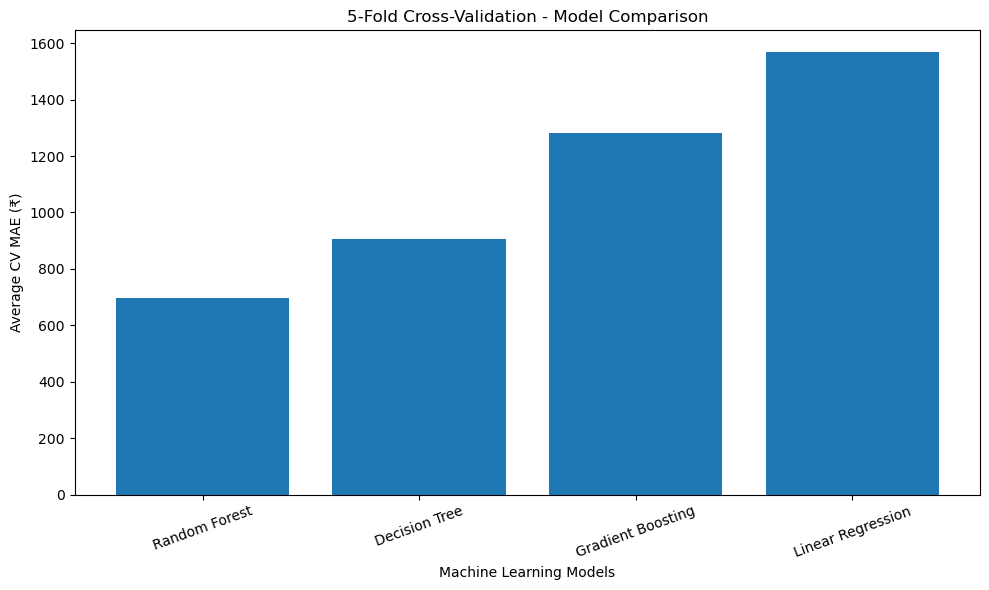

In [72]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_comparison_df['Model'],
    cv_comparison_df['CV_MAE']
)

plt.title('5-Fold Cross-Validation - Model Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Average CV MAE (₹)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


##  Model Comparison Report

### 1. Objective
The objective of this comparison is to evaluate multiple machine learning regression algorithms and identify the most suitable model for predicting flight ticket prices.

Four regression algorithms were evaluated:
- Linear Regression
- Decision Tree Regressor
- Gradient Boosting Regressor
- Random Forest Regressor

### 2. Evaluation Metrics

The models were evaluated using the following metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted ticket prices. A lower MAE indicates better prediction accuracy.
- **RMSE (Root Mean Squared Error):** Measures prediction errors while giving more weight to larger errors. A lower RMSE is better.
- **R² Score:** Measures how much variation in ticket prices is explained by the model. A score closer to 1 indicates a better fit.

### 3. Test Set Performance

| Model | MAE (₹) | RMSE (₹) | R² Score |
|---|---:|---:|---:|
| Linear Regression | 1542.86 | 2362.97 | 0.7301 |
| Decision Tree | 871.80 | 1736.92 | 0.8542 |
| Random Forest | 642.02 | 1349.72 | 0.9119 |
| Gradient Boosting | 1277.16 | 1936.12 | 0.8188 |

### 4. Five-Fold Cross-Validation Results

| Model | Average CV MAE (₹) | Average CV R² |
|---|---:|---:|
| Random Forest | 697.68 | 0.8774 |
| Decision Tree | 904.92 | 0.7983 |
| Gradient Boosting | 1280.87 | 0.8183 |
| Linear Regression | 1567.39 | 0.7380 |

### 5. Model Comparison and Findings

- Random Forest achieved the lowest test MAE of ₹642.02 and the lowest test RMSE of ₹1,349.72.
- It also achieved the highest test R² score of 0.9119.
- Cross-validation results confirmed its performance, with an average MAE of ₹697.68 and an average R² score of 0.8774.
- Decision Tree performed better than Linear Regression and Gradient Boosting in terms of test MAE.
- Linear Regression had the highest prediction error among the four evaluated models.

### 6. Recommended Model

Based on the test set and five-fold cross-validation results, **Random Forest Regressor is selected as the best-performing model** for this flight fare prediction project.

It provides the lowest prediction errors and the highest R² score among the evaluated models. Its cross-validation performance also indicates good consistency across different training folds.

### 7. Conclusion

The comparison demonstrates that tree-based ensemble learning, particularly Random Forest, performed better than the other evaluated regression algorithms on this dataset.

The selected model can estimate flight ticket prices using journey-related features such as airline, source, destination, route, number of stops, journey date, departure time, arrival time and duration.



## Challenges Report

### 1. Missing Values
**Challenge:** The dataset contained one record with missing values in the Route and Total_Stops columns.

**Technique Used:** The incomplete record was removed using `dropna()` on these two columns.

**Reason:** Route and number of stops are important journey-related features. Removing the single incomplete record avoided introducing assumptions or incorrect values.

### 2. Duplicate Records
**Challenge:** The original dataset contained 220 exact duplicate records.

**Technique Used:** Exact duplicates were identified using `duplicated()` and removed using `drop_duplicates()`.

**Reason:** Duplicate records can give repeated observations excessive influence during model training and affect evaluation.

### 3. Inconsistent Categorical Values
**Challenge:** The Additional_Info column contained inconsistent capitalization, such as "No Info" and "No info".

**Technique Used:** Text values were standardized using string operations and replacement.

**Reason:** Standardization prevents equivalent categories from being treated as separate values.

### 4. Duration Feature Processing
**Challenge:** Flight duration was originally stored as text, for example, hours and minutes. One record also contained an implausibly short duration of five minutes.

**Technique Used:** Duration was converted into numerical minutes. The record with duration below 30 minutes was excluded from the modelling dataset.

**Reason:** Machine learning algorithms require numerical input for this feature, and excluding the implausible observation avoids training on a suspicious journey duration.

### 5. Categorical Feature Encoding
**Challenge:** Features such as Airline, Source, Destination, Route and Additional_Info contained text categories.

**Technique Used:** OneHotEncoder was applied through a ColumnTransformer, with `handle_unknown='ignore'`.

**Reason:** Encoding converts categorical information into numerical form and allows the model to handle previously unseen categories without an encoding error.

### 6. Numerical Feature Scaling
**Challenge:** Numerical features had different ranges and units.

**Technique Used:** StandardScaler was applied to numerical features within the preprocessing pipeline.

**Reason:** Scaling puts numerical features on a comparable scale and supports consistent preprocessing across training and test data.

### 7. High Price Values and Outliers
**Challenge:** The ticket price distribution was right-skewed and contained some unusually high but potentially valid fares.

**Technique Used:** Price distribution was analysed using descriptive statistics and visualizations. Valid high-price records were not automatically removed.

**Reason:** High fares may represent genuine premium or business-class journeys. Removing them without evidence could result in loss of useful information.

### 8. High-Cardinality Route Feature
**Challenge:** The Route column contained 128 unique route combinations.

**Technique Used:** One-hot encoding was used to represent route categories.

**Reason:** This allows the model to learn route-specific patterns. `handle_unknown='ignore'` also supports categories not encountered during training.

### 9. Model Selection and Evaluation
**Challenge:** A single algorithm may not provide the best prediction performance.

**Technique Used:** Four regression algorithms were compared using MAE, RMSE and R². Five-fold cross-validation was also performed on the training data.

**Reason:** Comparing multiple models and cross-validation results provides stronger evidence for selecting a suitable model.

### 10. Dataset Limitations
**Challenge:** The dataset contains historical flight fare records from 2019, covering March to June. It does not contain repeated fare observations over time for the same journey.

**Technique Used:** The project was designed as a historical-data-based flight fare estimation model.

**Reason:** The available data supports estimating prices from journey attributes, but it does not support reliable forecasting of live fare fluctuations over future dates.

### Overall Conclusion
The dataset challenges were addressed through data cleaning, feature engineering, categorical encoding, numerical scaling and model evaluation. These techniques helped prepare the data for regression modelling and improve the reliability of the model comparison process.


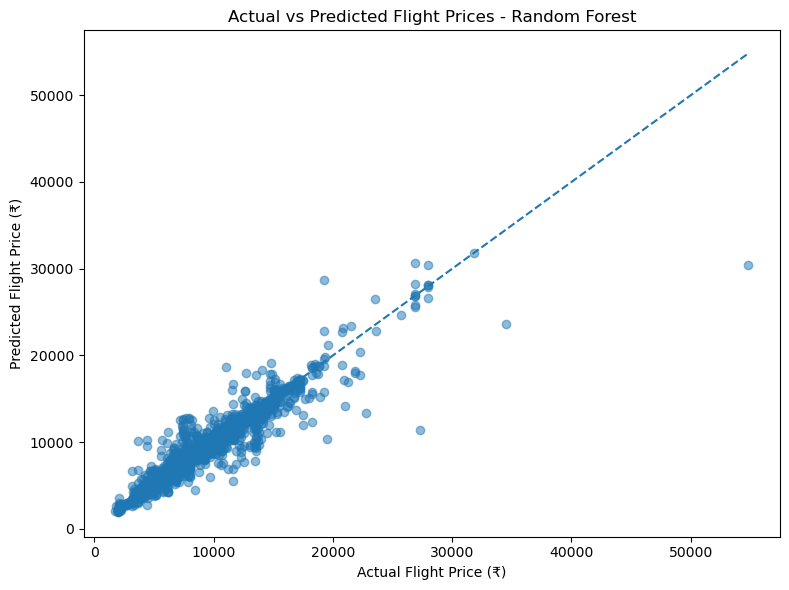

In [73]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted Flight Prices - Random Forest')
plt.xlabel('Actual Flight Price (₹)')
plt.ylabel('Predicted Flight Price (₹)')
plt.tight_layout()
plt.show()

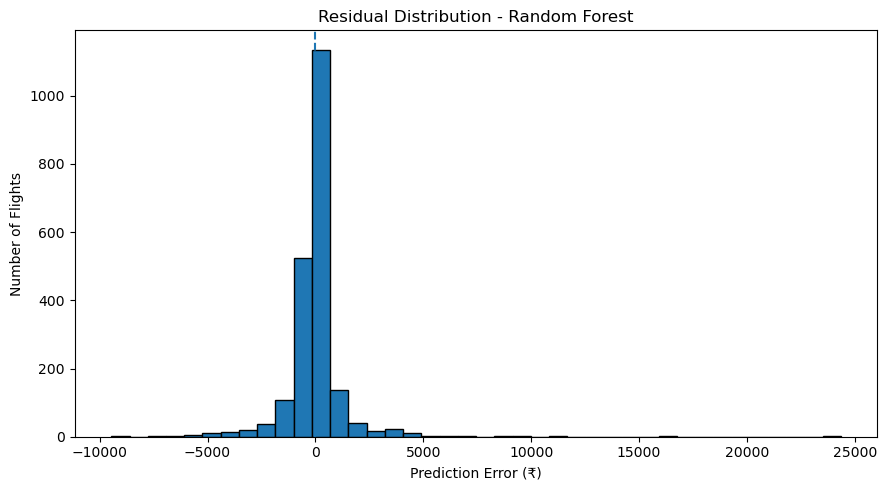

In [74]:
# Calculate prediction errors (residuals)
residuals = y_test - y_pred_rf

# Plot residual distribution
plt.figure(figsize=(9, 5))

plt.hist(
    residuals,
    bins=40,
    edgecolor='black'
)

plt.axvline(
    x=0,
    linestyle='--'
)

plt.title('Residual Distribution - Random Forest')
plt.xlabel('Prediction Error (₹)')
plt.ylabel('Number of Flights')

plt.tight_layout()
plt.show()

In [75]:
print("Residual Mean:", residuals.mean())
print("Residual Median:", residuals.median())
print("Residual Standard Deviation:", residuals.std())

print("Minimum Residual:", residuals.min())
print("Maximum Residual:", residuals.max())

print(
    "Predictions within ±₹1000:",
    (residuals.abs() <= 1000).mean() * 100,
    "%"
)

Residual Mean: -47.96078202936047
Residual Median: -19.576615719266556
Residual Standard Deviation: 1349.1881465958495
Minimum Residual: -9462.236042929297
Maximum Residual: 24357.805429834047
Predictions within ±₹1000: 82.51313903487817 %



### Residual Analysis - Findings

The residual analysis was performed to understand the prediction errors of the Random Forest Regressor.

Key observations:

- The mean residual was approximately -₹47.96, indicating a small average prediction bias.
- The median residual was approximately -₹19.58, showing that the typical residual was close to zero.
- The residual standard deviation was approximately ₹1,349.19.
- Approximately 82.51% of predictions had an absolute error within ₹1,000.
- A few predictions showed considerably larger errors, indicating that the model may struggle with certain flight categories or unusually high ticket prices.

**Conclusion:** The Random Forest model demonstrates good overall prediction performance, although some individual predictions have substantial errors. Therefore, predictions should be treated as estimates rather than guaranteed ticket prices.


In [76]:
# Select one sample flight from the test dataset
sample_flight = X_test.iloc[[0]]

# Predict its flight ticket price
sample_prediction = random_forest_pipeline.predict(sample_flight)

# Display journey details and predicted price
print("Sample Flight Details:")
display(sample_flight)

print("Predicted Flight Price: ₹", round(sample_prediction[0], 2))
print("Actual Flight Price: ₹", round(y_test.iloc[0], 2))

Sample Flight Details:


,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Duration_Minutes,Journey_Month,Journey_Day,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute
2150,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1,No info,1455,3,6,8,0,8,15


Predicted Flight Price: ₹ 15098.33
Actual Flight Price: ₹ 17996



### Sample Flight Fare Prediction

A sample flight record was selected from the test dataset to demonstrate the prediction capability of the trained Random Forest model.

**Flight Details:**
- Airline: Jet Airways
- Source: Banglore
- Destination: New Delhi
- Route: BLR → BOM → DEL
- Total Stops: 1
- Duration: 1455 minutes

**Prediction Results:**
- Predicted Flight Price: ₹15,098.33
- Actual Flight Price: ₹17,996.00
- Absolute Prediction Error: ₹2,897.67

**Observation:**

The model successfully generated a fare estimate using the selected journey details. The predicted price was lower than the actual price, resulting in an absolute error of ₹2,897.67.

This example demonstrates how the trained model can estimate flight fares, while also highlighting that individual predictions may differ from actual ticket prices.


In [77]:

# Saving the trained Random Forest model

import joblib

# Create model folder inside the project directory
model_folder = project_folder / "outputs" / "models"
model_folder.mkdir(parents=True, exist_ok=True)

# Save the trained Random Forest pipeline
model_path = model_folder / "flight_fare_random_forest.pkl"

joblib.dump(random_forest_pipeline, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())
print("Model file size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))


Model saved successfully!
Saved location: C:\Users\Rakshitha\OneDrive\Desktop\Flight-Fare-Prediction\outputs\models\flight_fare_random_forest.pkl
Model file size (MB): 39.72



# Final Project Conclusion

## Project: Flight Fare Prediction Using Machine Learning

### 1. Project Overview
The objective of this project was to analyse historical flight fare data and develop a machine learning model capable of estimating flight ticket prices based on journey-related attributes.

### 2. Data Analysis
The original dataset contained 10,683 records and 11 columns. Data cleaning, duplicate removal, missing-value handling and feature engineering were performed to prepare the dataset for analysis and modelling.

### 3. Machine Learning Models
Four regression algorithms were implemented and evaluated:
- Linear Regression
- Decision Tree Regressor
- Gradient Boosting Regressor
- Random Forest Regressor

### 4. Best Model
Random Forest Regressor was selected as the best-performing model.

Its test performance was:
- MAE: ₹642.02
- RMSE: ₹1,349.72
- R² Score: 0.9119

Five-fold cross-validation also supported its selection, with an average MAE of ₹697.68.

### 5. Model Validation
Actual vs Predicted analysis, residual analysis and a sample flight fare prediction were performed to assess the model's prediction behaviour.

Approximately 82.51% of test predictions had an absolute error within ₹1,000.

### 6. Model Deployment Readiness
The complete trained Random Forest pipeline, including preprocessing steps, was saved as:

`outputs/models/flight_fare_random_forest.pkl`

The saved pipeline can be loaded and reused for future fare estimation.

### 7. Project Limitations
- The dataset contains historical flight fare records from 2019, covering March to June.
- It does not contain live or repeated fare observations over time.
- Therefore, the model estimates fares based on journey attributes rather than forecasting dynamic future fare changes.
- Actual ticket prices may vary due to airline policies, demand, availability and booking conditions.

### 8. Final Conclusion
This project demonstrates the application of data analysis, data preprocessing, feature engineering and regression-based machine learning for flight fare estimation.

Among the four evaluated models, Random Forest Regressor achieved the strongest overall performance and was selected as the final model.

The project provided practical experience in building an end-to-end machine learning workflow, from raw data analysis to model evaluation and saving the trained model.


In [78]:

# Verifying the saved Random Forest model

import joblib

model_path = project_folder / "outputs" / "models" / "flight_fare_random_forest.pkl"

print("Expected Model Location:")
print(model_path.resolve())

print("\nModel Exists:", model_path.exists())

if model_path.exists():
    print(
        "Model File Size:",
        round(model_path.stat().st_size / (1024 * 1024), 2),
        "MB"
    )

    loaded_random_forest_model = joblib.load(model_path)

    print("\nSaved model loaded successfully!")
else:
    print("\nModel file was not found. Please run the model-saving cell again.")

Expected Model Location:
C:\Users\Rakshitha\OneDrive\Desktop\Flight-Fare-Prediction\outputs\models\flight_fare_random_forest.pkl

Model Exists: True
Model File Size: 39.72 MB

Saved model loaded successfully!
